<a href="https://colab.research.google.com/github/encen-ya/ML_2026/blob/main/TugasPraktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
# Tugas Praktikum

## Tugas 1 - K-Means pada `Mall_Customers.csv`

Ketentuan: (1) gunakan `Mall_Customers.csv`, (2) tentukan fitur yang tepat (minimal 2), (3) buat model K-Means dengan jumlah *k* terbaik.

### 1.1 Eksplorasi data

In [2]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

RANDOM_STATE = 42

butuh = [f for f in ['Mall_Customer.csv'] if not os.path.exists(f)]
if butuh:
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        print('File belum ditemukan:')
else:
    print('Semua dataset tersedia.')

Saving Mall_Customers.csv to Mall_Customers.csv


In [3]:
mall = pd.read_csv('Mall_Customers.csv')
print(mall.shape)
display(mall.head())
display(mall.describe())
print(mall.isnull().sum())

(200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


### 1.2 Pemilihan fitur

K-Means memakai jarak Euclidean, sehingga fitur harus **numerik**. `CustomerID` hanyalah identitas dan `Gender` bersifat kategorik, sehingga keduanya tidak dipakai. Kandidat fitur numerik: `Age`, `Annual Income (k$)`, `Spending Score (1-100)`. Dua kombinasi dibandingkan secara visual dan dengan Silhouette pada langkah berikutnya.

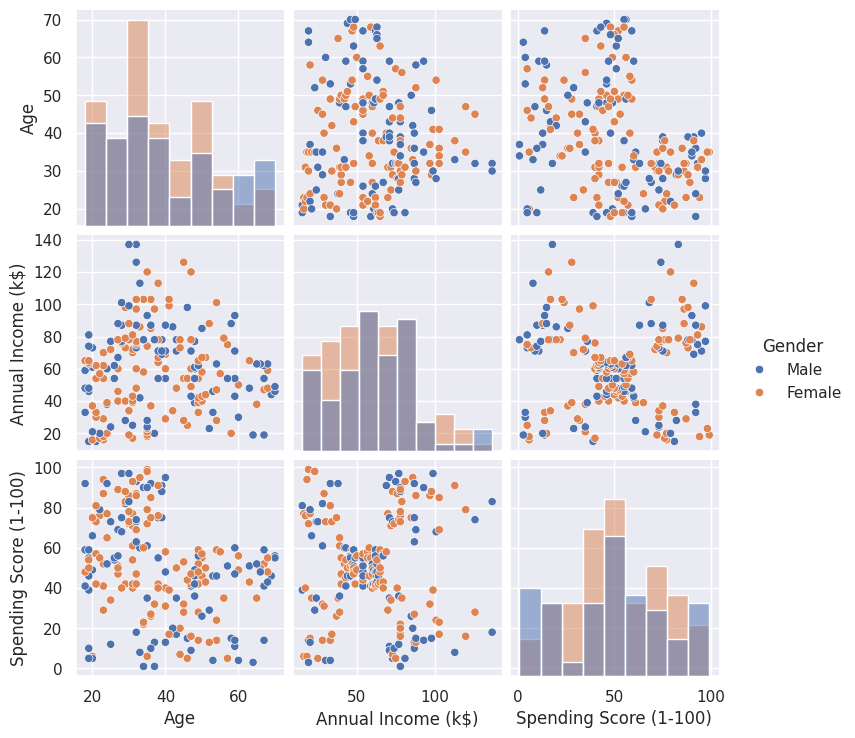

In [7]:
fitur_numerik = ['Age', 'Annual Income (k$)', 'Spending Score (1-100)']
sns.pairplot(mall[fitur_numerik + ['Gender']], hue='Gender', diag_kind='hist')
plt.show()

### 1.3 Menentukan k terbaik (Elbow + Silhouette)

Fitur dipilih: **Annual Income** dan **Spending Score**, lalu distandardisasi agar skala keduanya setara.

,k,SSE,Silhouette
0,2,269.6910,0.3213
1,3,157.7040,0.4666
2,4,108.9213,0.4939
3,5,65.5684,0.5547
4,6,55.0573,0.5399
5,7,44.8648,0.5281
6,8,37.2282,0.4552
7,9,32.3923,0.4571
8,10,29.9819,0.4432


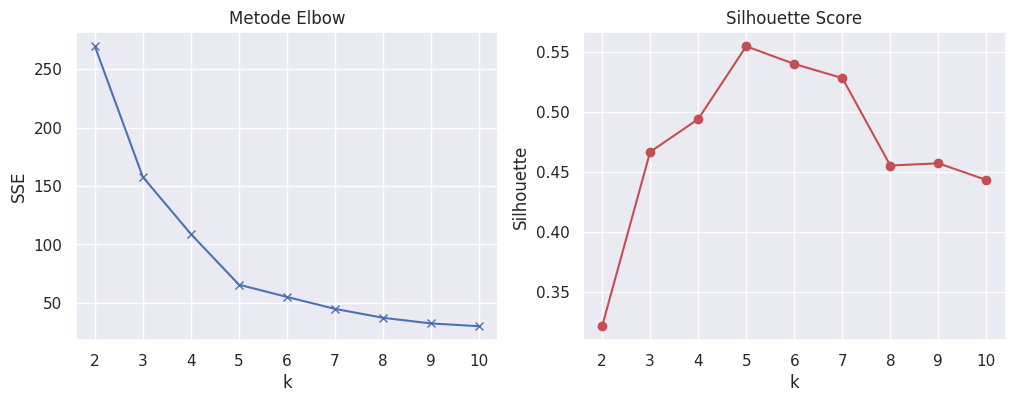

k dengan Silhouette tertinggi: 5


In [8]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

fitur = ['Annual Income (k$)', 'Spending Score (1-100)']
Xm = mall[fitur].values
Xm_s = StandardScaler().fit_transform(Xm)

K = range(2, 11)
sse_m, sil_m = [], []
for k in K:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xm_s)
    sse_m.append(km.inertia_)
    sil_m.append(silhouette_score(Xm_s, km.labels_))

hasil_k = pd.DataFrame({'k': list(K), 'SSE': sse_m, 'Silhouette': sil_m})
display(hasil_k.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(K, sse_m, 'bx-'); ax[0].set(xlabel='k', ylabel='SSE', title='Metode Elbow')
ax[1].plot(K, sil_m, 'ro-'); ax[1].set(xlabel='k', ylabel='Silhouette', title='Silhouette Score')
plt.show()

k_terbaik = int(hasil_k.loc[hasil_k['Silhouette'].idxmax(), 'k'])
print('k dengan Silhouette tertinggi:', k_terbaik)

### 1.4 Membandingkan pilihan fitur

In [9]:
kombinasi = {
    'Income + Spending':       ['Annual Income (k$)', 'Spending Score (1-100)'],
    'Age + Spending':          ['Age', 'Spending Score (1-100)'],
    'Age + Income':            ['Age', 'Annual Income (k$)'],
    'Age + Income + Spending': ['Age', 'Annual Income (k$)', 'Spending Score (1-100)'],
}
baris = []
for nama, cols in kombinasi.items():
    Z = StandardScaler().fit_transform(mall[cols])
    for k in range(2, 9):
        lab = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(Z)
        baris.append((nama, k, silhouette_score(Z, lab)))
cmp_df = pd.DataFrame(baris, columns=['Fitur', 'k', 'Silhouette'])
ringkas = cmp_df.loc[cmp_df.groupby('Fitur')['Silhouette'].idxmax()].reset_index(drop=True)
display(ringkas.round(4))

,Fitur,k,Silhouette
0,Age + Income,3,0.4431
1,Age + Income + Spending,6,0.4284
2,Age + Spending,2,0.4721
3,Income + Spending,5,0.5547


### 1.5 Model akhir dan visualisasi

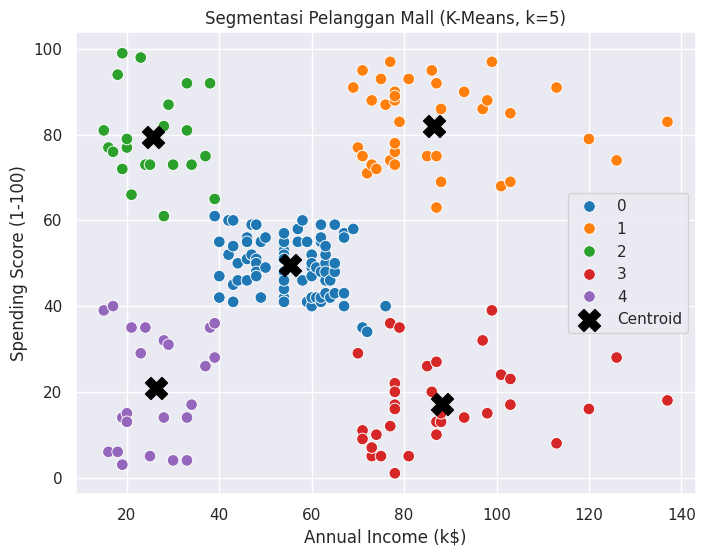

Silhouette model akhir: 0.5547


In [12]:
kmeans_final = KMeans(n_clusters=k_terbaik, n_init=10, random_state=RANDOM_STATE)
mall['Cluster'] = kmeans_final.fit_predict(Xm_s)

pusat = StandardScaler().fit(Xm).inverse_transform(kmeans_final.cluster_centers_)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=fitur[0], y=fitur[1], hue='Cluster', data=mall,
                palette='tab10', s=70)
plt.scatter(pusat[:, 0], pusat[:, 1], c='black', s=250, marker='X', label='Centroid')
plt.title(f'Segmentasi Pelanggan Mall (K-Means, k={k_terbaik})')
plt.legend()
plt.show()

print('Silhouette model akhir:', round(silhouette_score(Xm_s, mall['Cluster']), 4))

In [11]:
# Profil tiap klaster
profil = mall.groupby('Cluster').agg(
    jumlah=('CustomerID', 'count'),
    rata2_usia=('Age', 'mean'),
    rata2_income=('Annual Income (k$)', 'mean'),
    rata2_spending=('Spending Score (1-100)', 'mean'),
).round(1)
profil

,jumlah,rata2_usia,rata2_income,rata2_spending
Cluster,,,,
0,81,42.7,55.3,49.5
1,39,32.7,86.5,82.1
2,22,25.3,25.7,79.4
3,35,41.1,88.2,17.1
4,23,45.2,26.3,20.9


## Tugas 2 - DBSCAN pada `make_moons`

### 2.1 Dataset make_moons (1000 sampel, noise=0.05) dan normalisasi

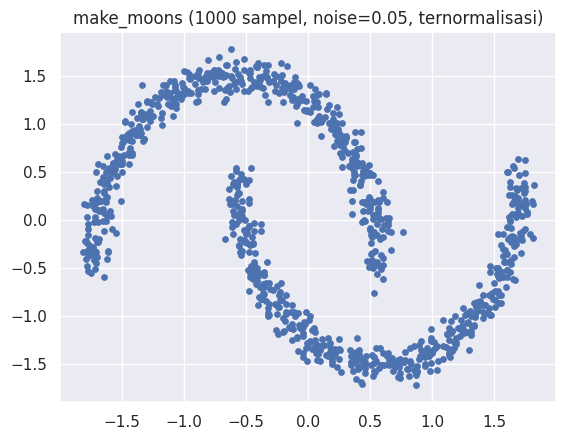

In [13]:
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn import metrics
from sklearn.cluster import DBSCAN

Xm2, y_true2 = make_moons(n_samples=1000, noise=0.05, random_state=0)
Xm2 = StandardScaler().fit_transform(Xm2)

plt.scatter(Xm2[:, 0], Xm2[:, 1], s=15)
plt.title('make_moons (1000 sampel, noise=0.05, ternormalisasi)')
plt.show()

### 2.2 DBSCAN dengan eps=0.2, min_samples=5

In [14]:
db2 = DBSCAN(eps=0.2, min_samples=5).fit(Xm2)
lab2 = db2.labels_
n_cl = len(set(lab2)) - (1 if -1 in lab2 else 0)
n_ns = list(lab2).count(-1)
print('Jumlah klaster :', n_cl)
print('Jumlah noise   :', n_ns)

Jumlah klaster : 2
Jumlah noise   : 0


### 2.3 Evaluasi

In [15]:
def evaluasi(X, labels_true, labels):
    """Enam metrik evaluasi. Silhouette = NaN bila klaster < 2."""
    n_unik = len(set(labels))
    sil = metrics.silhouette_score(X, labels) if n_unik >= 2 else float('nan')
    return {
        'Homogeneity': metrics.homogeneity_score(labels_true, labels),
        'Completeness': metrics.completeness_score(labels_true, labels),
        'V-measure': metrics.v_measure_score(labels_true, labels),
        'ARI': metrics.adjusted_rand_score(labels_true, labels),
        'AMI': metrics.adjusted_mutual_info_score(labels_true, labels),
        'Silhouette': sil,
    }

for nama, nilai in evaluasi(Xm2, y_true2, lab2).items():
    print(f'{nama:13s}: {nilai:.3f}')

Homogeneity  : 1.000
Completeness : 1.000
V-measure    : 1.000
ARI          : 1.000
AMI          : 1.000
Silhouette   : 0.392


### 2.4 Visualisasi (core = besar, non-core = kecil, noise = hitam)

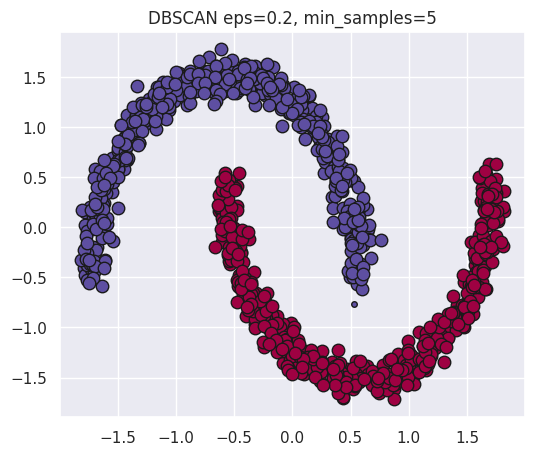

In [16]:
def plot_dbscan(X, db, ax=None, judul=''):
    labels = db.labels_
    unique_labels = sorted(set(labels))
    core_mask = np.zeros_like(labels, dtype=bool)
    core_mask[db.core_sample_indices_] = True
    n_cl = len(set(labels)) - (1 if -1 in labels else 0)
    cols = [plt.cm.Spectral(e) for e in np.linspace(0, 1, len(unique_labels))]
    if ax is None:
        ax = plt.gca()
    for k, col in zip(unique_labels, cols):
        if k == -1:
            col = [0, 0, 0, 1]
        m = labels == k
        xy = X[m & core_mask]
        ax.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
                markeredgecolor='k', markersize=9)
        xy = X[m & ~core_mask]
        ax.plot(xy[:, 0], xy[:, 1], 'o', markerfacecolor=tuple(col),
                markeredgecolor='k', markersize=4)
    ax.set_title(judul or f'Estimated number of clusters: {n_cl}')

plt.figure(figsize=(6, 5))
plot_dbscan(Xm2, db2, judul='DBSCAN eps=0.2, min_samples=5')
plt.show()

### 2.5 Eksperimen parameter

`eps` = 0.05, 0.1, 0.3, 0.5 dan `min_samples` = 3, 10, 20 (12 kombinasi).

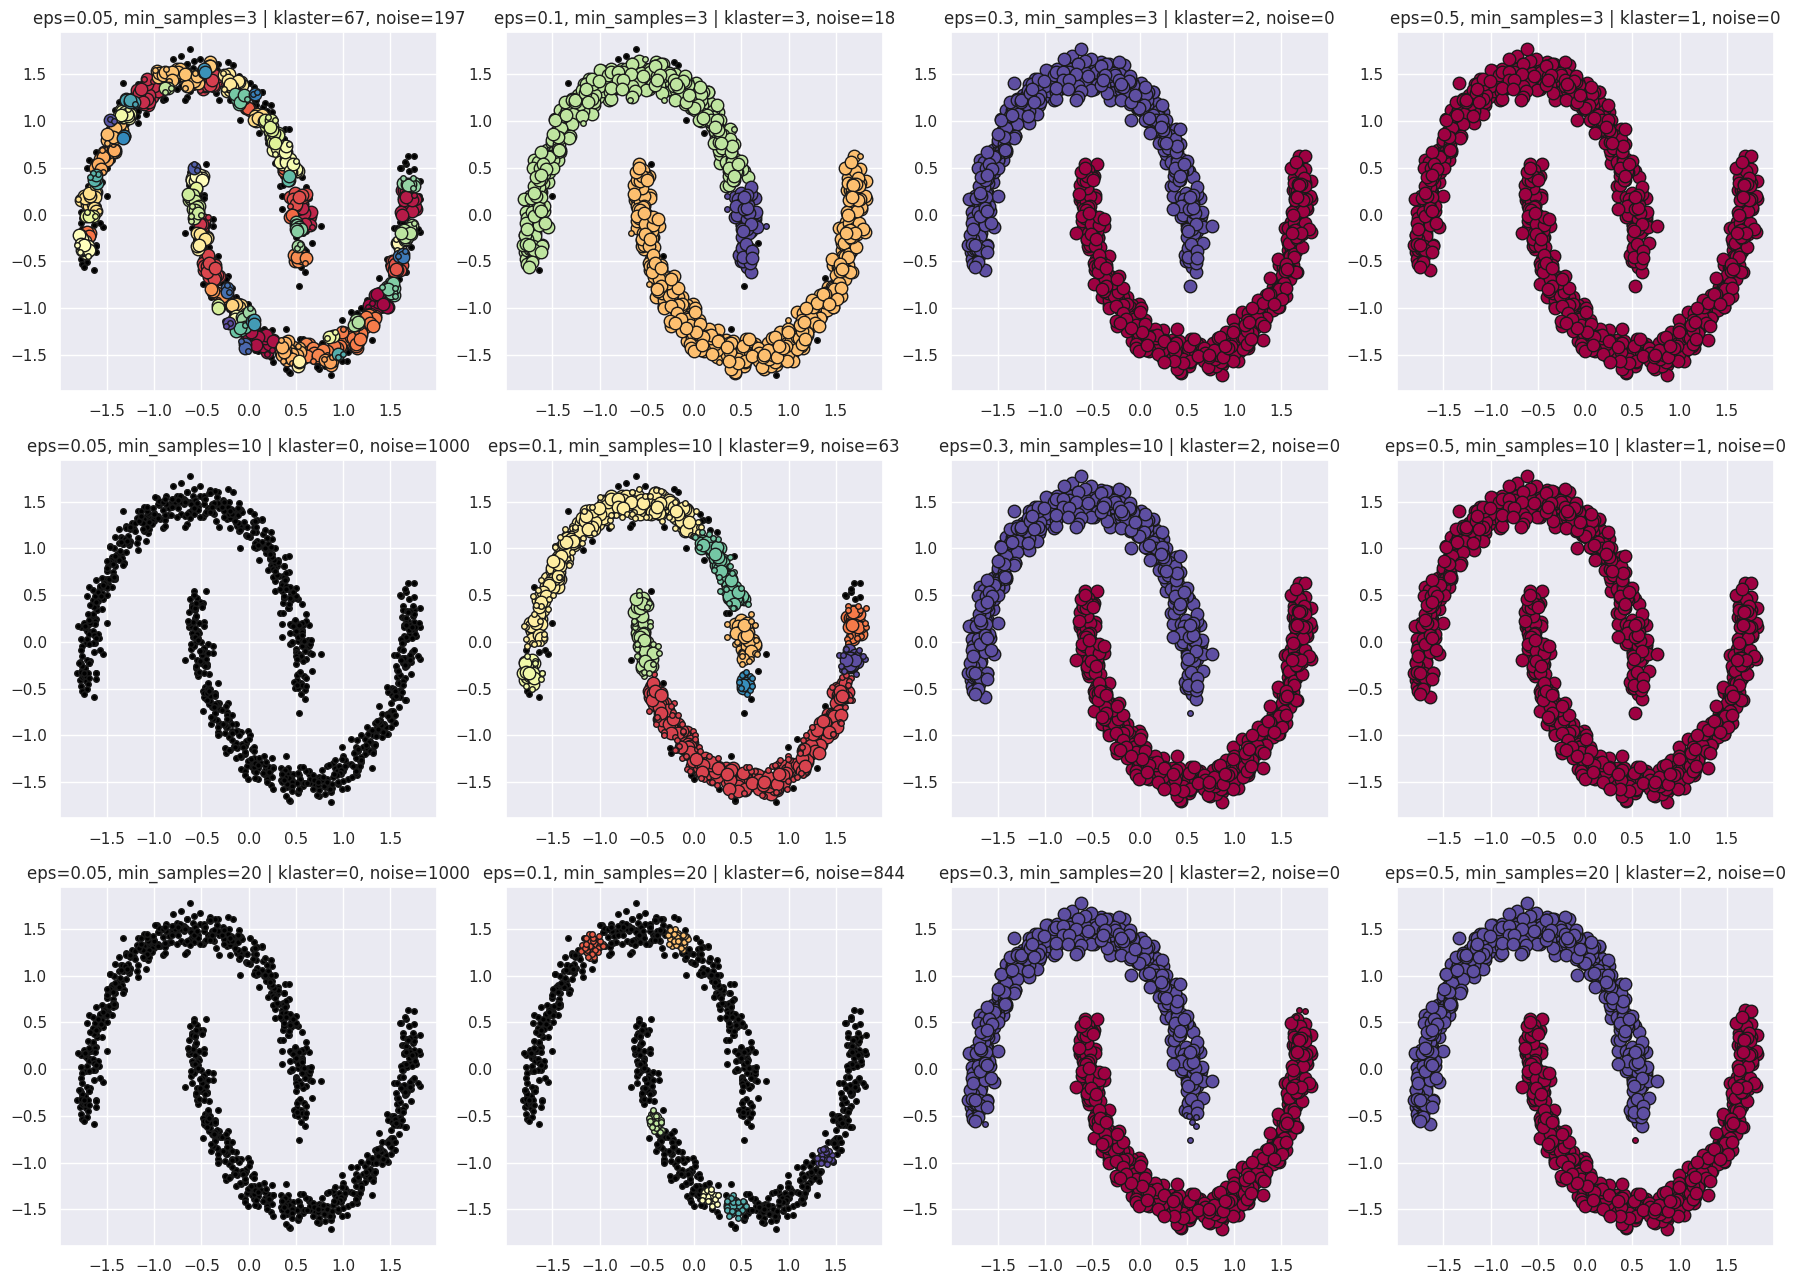

,eps,min_samples,klaster,noise,Homogeneity,Completeness,V-measure,ARI,AMI,Silhouette
0,0.05,3,67,197,0.804,0.155,0.260,0.033,0.246,0.078
1,0.10,3,3,18,0.983,0.708,0.824,0.854,0.823,0.138
2,0.30,3,2,0,1.000,1.000,1.000,1.000,1.000,0.392
3,0.50,3,1,0,0.000,1.000,0.000,0.000,0.000,NaN
4,0.05,10,0,1000,0.000,1.000,0.000,0.000,0.000,NaN
5,0.10,10,9,63,0.939,0.358,0.519,0.435,0.517,0.184
6,0.30,10,2,0,1.000,1.000,1.000,1.000,1.000,0.392
7,0.50,10,1,0,0.000,1.000,0.000,0.000,0.000,NaN
8,0.05,20,0,1000,0.000,1.000,0.000,0.000,0.000,NaN
9,0.10,20,6,844,0.157,0.153,0.155,0.010,0.152,-0.409


In [ ]:
eps_list = [0.05, 0.1, 0.3, 0.5]
ms_list = [3, 10, 20]

hasil = []
fig, axes = plt.subplots(len(ms_list), len(eps_list), figsize=(18, 13))
for i, ms in enumerate(ms_list):
    for j, eps in enumerate(eps_list):
        d = DBSCAN(eps=eps, min_samples=ms).fit(Xm2)
        lb = d.labels_
        n_c = len(set(lb)) - (1 if -1 in lb else 0)
        n_n = int((lb == -1).sum())
        ev = evaluasi(Xm2, y_true2, lb)
        hasil.append({'eps': eps, 'min_samples': ms, 'klaster': n_c, 'noise': n_n, **ev})
        plot_dbscan(Xm2, d, ax=axes[i, j], judul=f'eps={eps}, min_samples={ms} | klaster={n_c}, noise={n_n}')
plt.tight_layout()
plt.show()

tabel = pd.DataFrame(hasil)
tabel.round(3)